In [2]:
%load_ext autoreload
%autoreload 2

# 1. IMPORT LIBRARIES AND SET STATIC VARIABLES

In [3]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from fredapi import Fred
import yfinance as yf
from scipy.optimize import minimize

In [4]:
FED_API_KEY="79b300c57b4893f902328303a135d4a1"

# 2.INITIALIZE DATA 

In [5]:
# Source : Google Sheets privé STRATEGY_ANALYSIS (authentification Google sur le Mac)
# Prérequis : pip install google-auth requests openpyxl
# Première connexion : gcloud auth application-default login --scopes=https://www.googleapis.com/auth/drive.readonly,https://www.googleapis.com/auth/cloud-platform
from io import BytesIO
import google.auth
from google.auth.transport.requests import AuthorizedSession

STRATEGY_SHEET_ID = '1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0'
credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
session = AuthorizedSession(credentials)
response = session.get(
    f'https://www.googleapis.com/drive/v3/files/{STRATEGY_SHEET_ID}/export',
    params={'mimeType': 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'},
    timeout=120,
)
response.raise_for_status()
strategy_excel = BytesIO(response.content)

data = pd.read_excel(strategy_excel, sheet_name='EQUITY BACKTEST STRATEGY', skiprows=3, usecols=[0, 1, 4])

In [6]:
data

,Date,Close,Close.1
0,1998-12-31 16:00:00.288,1229.40,1.1680
1,1999-01-08 16:00:00.288,1275.09,1.1580
2,1999-01-14 16:00:00.288,1212.19,1.1560
3,1999-01-22 16:00:00.288,1225.19,1.1585
4,1999-01-29 16:00:00.288,1279.64,1.1365
...,...,...,...
1347,2024-11-15 16:00:00.288,5870.62,1.0801
1348,2024-11-22 16:00:00.288,5969.34,1.0873
1349,NaT,NaN,1.0717
1350,NaT,NaN,1.0543


In [7]:
def convert_df_date(data):
    # Format the 'Date' column to show only the date (YYYY-MM-DD)
    data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')
    # Set 'Date' as the index

    data.index=pd.to_datetime(data.index, errors='coerce')
    return data

In [8]:
# Format the 'Date' column to show only the date (YYYY-MM-DD)
data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')
# Set 'Date' as the index
data.set_index('Date', inplace=True)
data.index=pd.to_datetime(data.index, errors='coerce')

# Rename columns 'Close' to 'SPX' and 'Close.1' to 'EURUSD'
data.rename(columns={'Close': 'SPX', 'Close.1': 'EURUSD'}, inplace=True)
data.dropna(inplace=True)

In [9]:
data.index

DatetimeIndex(['1998-12-31', '1999-01-08', '1999-01-14', '1999-01-22',
               '1999-01-29', '1999-02-05', '1999-02-12', '1999-02-19',
               '1999-02-26', '1999-03-05',
               ...
               '2024-09-20', '2024-09-27', '2024-10-04', '2024-10-10',
               '2024-10-18', '2024-10-25', '2024-11-01', '2024-11-08',
               '2024-11-15', '2024-11-22'],
              dtype='datetime64[ns]', name='Date', length=1349, freq=None)

In [10]:
# Assuming the DataFrame is called 'data', and it contains the 'SPX' column
DVIDEND_YIELD = 0.02  # Example: 2% annual dividend yield
initial_value = data['SPX'].iloc[0]  # Assume SPXTR starts equal to the first value of SPX

# Create SPXTR column and initialize the first value
data['SPXTR'] = 0
data.loc[data.index[0], 'SPXTR'] = initial_value

# Loop over rows to calculate SPXTR based on the formula provided
for i in range(1, len(data)):
    data.loc[data.index[i], 'SPXTR'] = data.loc[data.index[i-1], 'SPXTR'] * (
        1 + (data.loc[data.index[i], 'SPX'] - data.loc[data.index[i-1], 'SPX']) / data.loc[data.index[i-1], 'SPX'] 
        + DVIDEND_YIELD / 52
    )


/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_1795/309903971.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '1229.4' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[data.index[0], 'SPXTR'] = initial_value


In [11]:
data

,SPX,EURUSD,SPXTR
Date,,,
1998-12-31,1229.40,1.1680,1229.400000
1999-01-08,1275.09,1.1580,1275.562846
1999-01-14,1212.19,1.1560,1213.130122
1999-01-22,1225.19,1.1585,1226.606793
1999-01-29,1279.64,1.1365,1281.591530
...,...,...,...
2024-10-25,5808.12,1.0981,9734.205034
2024-11-01,5728.80,1.0943,9605.011427
2024-11-08,5995.54,1.0870,10055.926851


In [12]:
# Create the TRCompo column by dividing SPXTR by EURUSD
data['TRCompo'] = data['SPXTR'] / data['EURUSD']

In [13]:
data

,SPX,EURUSD,SPXTR,TRCompo
Date,,,,
1998-12-31,1229.40,1.1680,1229.400000,1052.568493
1999-01-08,1275.09,1.1580,1275.562846,1101.522320
1999-01-14,1212.19,1.1560,1213.130122,1049.420521
1999-01-22,1225.19,1.1585,1226.606793,1058.788772
1999-01-29,1279.64,1.1365,1281.591530,1127.665226
...,...,...,...,...
2024-10-25,5808.12,1.0981,9734.205034,8864.588867
2024-11-01,5728.80,1.0943,9605.011427,8777.310999
2024-11-08,5995.54,1.0870,10055.926851,9251.082659


In [14]:
# Calculate returns for each column
data['SPX_return'] = data['SPX'].pct_change()  # Percentage change for SPX
data['USDEUR_return'] = -data['EURUSD'].pct_change()  # Percentage change for EURUSD
data['SPXTR_return'] = data['SPXTR'].pct_change()  # Percentage change for SPXTR
data['TRCompo_return'] = data['TRCompo'].pct_change()  # Percentage change for SPXTR
data.dropna(inplace=True)
# Calculate standard deviation of returns
spx_std = round(data['SPX_return'].std()*100*np.sqrt(52),2)
eurusd_std = round(data['USDEUR_return'].std()*100*np.sqrt(52),2)
spxtr_std = round(data['SPXTR_return'].std()*100*np.sqrt(52),2)
spxtr_compo_std = round(data['TRCompo_return'].std()*100*np.sqrt(52),2)

# Print the standard deviations
print(f"Standard deviation of SPX returns: {spx_std}")
print(f"Standard deviation of EURUSD returns: {eurusd_std}")
print(f"Standard deviation of SPXTR returns: {spxtr_std}")
print(f"Standard deviation of SPXTR Composite EURO returns: {spxtr_compo_std}")

Standard deviation of SPX returns: 17.87
Standard deviation of EURUSD returns: 9.36
Standard deviation of SPXTR returns: 17.87
Standard deviation of SPXTR Composite EURO returns: 19.47


In [15]:
# seta weekly crash flag
ALPHA=-0.1
data['Crash'] = data['SPX_return'] < ALPHA

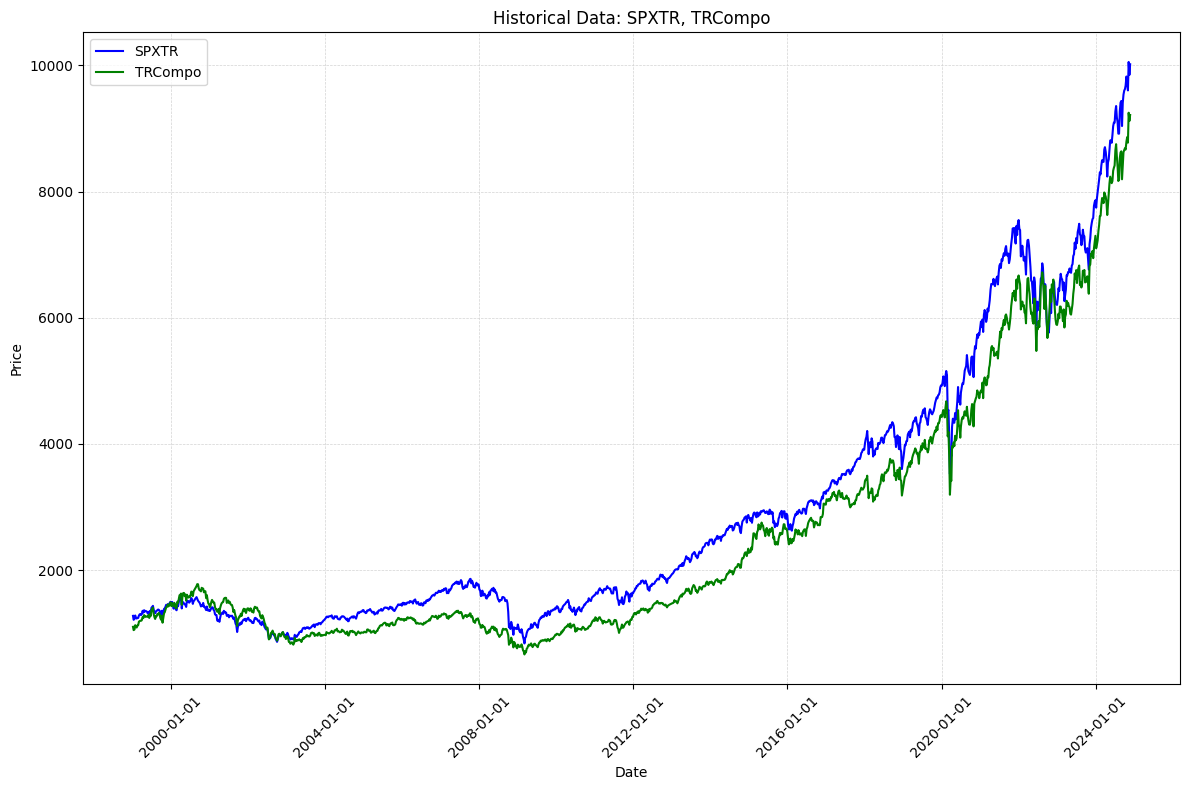

In [16]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# Set plot style
plt.style.use('default')

# Plot the data
plt.figure(figsize=(12, 8))
plt.plot(data.index, data['SPXTR'], label='SPXTR', color='blue')
plt.plot(data.index, data['TRCompo'], label='TRCompo', color='green')

# Format the x-axis for dates
plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())  # Automatically choose appropriate ticks
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as 'YYYY-MM-DD'

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Add labels, title, and legend
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Historical Data: SPXTR, TRCompo')
plt.legend()

# Add gridlines
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Show the plot
plt.tight_layout()  # Adjust layout to prevent label clipping
plt.show()


In [17]:
data.describe()

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return
count,1348.000000,1348.000000,1348.000000,1348.000000,1348.000000,1348.000000,1348.000000,1348.000000
mean,2069.126447,1.185464,2920.046542,2547.659339,0.001483,-0.000031,0.001868,0.001977
std,1208.978381,0.155529,2154.138033,1994.664996,0.024784,0.012979,0.024784,0.026994
min,683.380000,0.837200,838.442584,663.587324,-0.181955,-0.053917,-0.181570,-0.163427
25%,1212.122500,1.085450,1364.987737,1139.711961,-0.010693,-0.008219,-0.010308,-0.012776
50%,1457.645000,1.176600,1778.909268,1485.194320,0.002716,-0.000000,0.003100,0.002628
75%,2706.867500,1.302950,3998.790373,3405.792674,0.014598,0.007888,0.014983,0.017341
max,5995.540000,1.594100,10055.926851,9251.082659,0.121017,0.058552,0.121402,0.161106


In [18]:
# Define the window for 5 years (assuming monthly data, this is 60 months)
WINDOW_SIZE = 260

In [19]:
# Create an empty DataFrame for storing the rolling performance
rolling_performance_5Y = pd.DataFrame(index=data.index)

# Loop through the data, starting at the index equal to WINDOW_SIZE
for i in range(WINDOW_SIZE, len(data)):
    # Use the actual Date-based index, not the integer index
    rolling_performance_5Y.loc[data.index[i], 'Rolling5YPerf'] =round( 100* ( data.loc[data.index[i], 'TRCompo'] 
                                                                      / data.loc[data.index[i-WINDOW_SIZE], 'TRCompo'] - 1),2)


rolling_performance_5Y.dropna(inplace=True)




In [20]:
rolling_performance_5Y.describe()

,Rolling5YPerf
count,1088.000000
mean,58.340018
std,60.583393
min,-38.810000
25%,-3.922500
50%,77.140000
75%,110.627500
max,176.660000


In [21]:
rolling_performance_5Y.index

DatetimeIndex(['2004-01-02', '2004-01-09', '2004-01-16', '2004-01-23',
               '2004-01-30', '2004-02-06', '2004-02-13', '2004-02-20',
               '2004-02-27', '2004-03-05',
               ...
               '2024-09-20', '2024-09-27', '2024-10-04', '2024-10-10',
               '2024-10-18', '2024-10-25', '2024-11-01', '2024-11-08',
               '2024-11-15', '2024-11-22'],
              dtype='datetime64[ns]', name='Date', length=1088, freq=None)

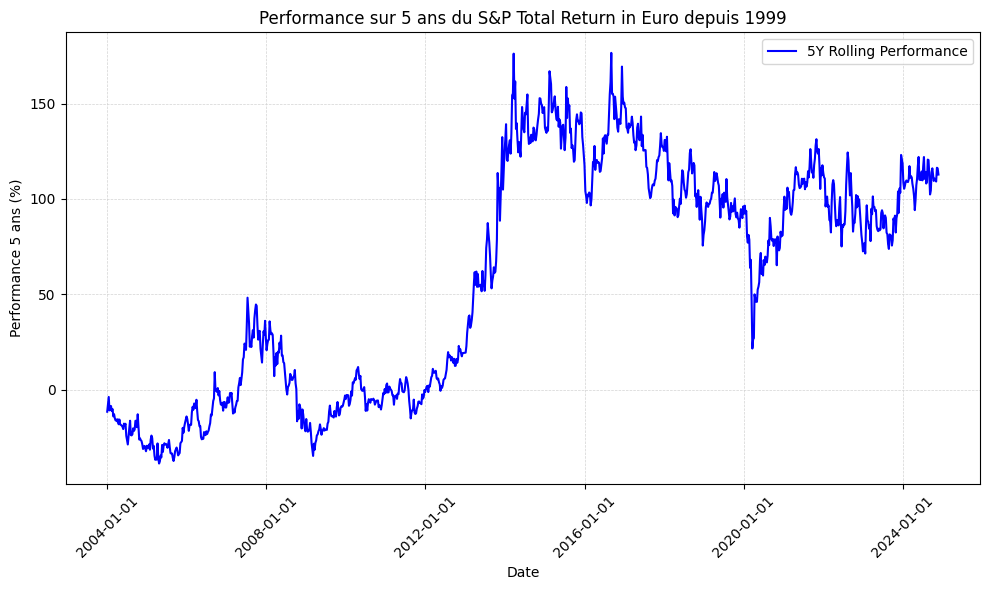

In [22]:

# Ensure the index is a datetime object
rolling_performance_5Y.index = pd.to_datetime(rolling_performance_5Y.index)

# Plot the 5-year rolling performance
plt.figure(figsize=(10, 6))
plt.plot(rolling_performance_5Y.index, rolling_performance_5Y['Rolling5YPerf'], label='5Y Rolling Performance', color='blue')

# Customize the plot
plt.title('Performance sur 5 ans du S&P Total Return in Euro depuis 1999')
plt.xlabel('Date')
plt.ylabel('Performance 5 ans (%)')
plt.legend()

# Format the x-axis for dates
plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())  # Automatically choose appropriate ticks
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as 'YYYY-MM-DD'

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Add gridlines
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Show the plot
plt.tight_layout()
plt.savefig("./results/5Y_SPX_Roll.png", dpi=300, bbox_inches="tight")
plt.show()


In [23]:
# Calculate the standard deviation of returns for each column
annual_volatility=round(spxtr_compo_std,2)
annualized_median_return = round(float(rolling_performance_5Y.median().iloc[0]/5),2)
annualized_mean_return = round(float(rolling_performance_5Y.mean().iloc[0]/5),2)

# Display the standard deviation of returns
print(f"Annualized volatility of strategy: {annual_volatility}%")
print(f"Annualized Median Return of strategy: {annualized_median_return}%")
print(f"Annualized Mean Return of strategy: {annualized_mean_return}%")



Annualized volatility of strategy: 19.47%
Annualized Median Return of strategy: 15.43%
Annualized Mean Return of strategy: 11.67%


In [24]:
annual_volatility

19.47

In [25]:
OBLIG_RETURN=6
OBLIG_RATIO=0.6
combo_return= OBLIG_RATIO * OBLIG_RETURN + (1-OBLIG_RATIO)  * annualized_median_return
combo_return

9.772

In [26]:
combo_vol = round((1-OBLIG_RATIO)  * annual_volatility,2)
sharp_ratio=round(combo_return/combo_vol,2)

In [27]:
combo_return,combo_vol, sharp_ratio

(9.772, 7.79, 1.25)

In [28]:
# Assuming 'data' is your DataFrame, and you want to calculate correlation between 'Column1' and 'Column2'
correlation = round(data['SPX_return'].corr(data['USDEUR_return'])*100,2)

In [29]:
print(f"Correlation S&P vs EURUSD FX: {correlation}%")

Correlation S&P vs EURUSD FX: -8.6%


In [30]:
data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash
Date,,,,,,,,,
1999-01-08,1275.09,1.1580,1275.562846,1101.522320,0.037164,0.008562,0.037549,0.046509,False
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False
...,...,...,...,...,...,...,...,...,...
2024-10-25,5808.12,1.0981,9734.205034,8864.588867,-0.009642,0.016920,-0.009258,0.007794,False
2024-11-01,5728.80,1.0943,9605.011427,8777.310999,-0.013657,0.003461,-0.013272,-0.009846,False
2024-11-08,5995.54,1.0870,10055.926851,9251.082659,0.046561,0.006671,0.046946,0.053977,False


In [31]:
# Filter the data where Crash is True
filtered_data = data[data['Crash'] == True]

# Calculate the correlation between the two columns on the filtered data
correlation = round(filtered_data['SPX_return'].corr(filtered_data['USDEUR_return'])*100,2)

# Display the correlation
print(f"Correlation between S&P and USDEUR FX during crashes: {correlation}%")


Correlation between S&P and USDEUR FX during crashes: -39.85%


# COMPARISON vs. SX5E

In [32]:
data_SX5E = pd.read_excel(strategy_excel, sheet_name='vsSTOXX50E', skiprows=3, usecols=[0, 1, 3, 5])

In [33]:
data_SX5E.dropna(inplace=True)

In [34]:
data_SX5E

,Date,Close,Close.1,Close.2
0,2010-01-15 16:00:00.288,1136.03,1.43860,2940.25
1,2010-01-22 16:00:00.288,1115.49,1.41500,2836.80
2,2010-01-29 16:00:00.288,1073.87,1.38610,2776.83
3,2010-02-05 16:00:00.288,1066.19,1.36040,2631.64
4,2010-02-12 16:00:00.288,1075.51,1.36161,2674.46
...,...,...,...,...
766,2024-10-10 16:00:00.288,5780.05,1.11690,4943.09
767,2024-10-18 16:00:00.288,5864.67,1.11700,4877.75
768,2024-10-25 16:00:00.288,5808.12,1.09810,4802.76
769,2024-11-01 16:00:00.288,5728.80,1.09430,4794.85


In [35]:
data_SX5E['Date'] = data_SX5E['Date'].dt.strftime('%Y-%m-%d')
# Set 'Date' as the index
data_SX5E.set_index('Date', inplace=True)
data_SX5E.index=pd.to_datetime(data_SX5E.index, errors='coerce')

# Rename columns 'Close' to 'SPX' and 'Close.1' to 'EURUSD'
data_SX5E.rename(columns={'Close': 'SPX', 'Close.1': 'EURUSD', 'Close.2': 'SX5E' }, inplace=True)

In [36]:
data_SX5E

,SPX,EURUSD,SX5E
Date,,,
2010-01-15,1136.03,1.43860,2940.25
2010-01-22,1115.49,1.41500,2836.80
2010-01-29,1073.87,1.38610,2776.83
2010-02-05,1066.19,1.36040,2631.64
2010-02-12,1075.51,1.36161,2674.46
...,...,...,...
2024-10-10,5780.05,1.11690,4943.09
2024-10-18,5864.67,1.11700,4877.75
2024-10-25,5808.12,1.09810,4802.76


In [37]:
data_SX5E['SPX_EUR'] = data_SX5E['SPX'] / data_SX5E['EURUSD']

In [38]:
data_SX5E.tail(20)

,SPX,EURUSD,SX5E,SPX_EUR
Date,,,,
2024-06-28,5460.48,1.0805,5043.02,5053.660342
2024-07-05,5567.19,1.0716,4827.24,5195.212766
2024-07-12,5615.35,1.0691,4862.50,5252.408568
2024-07-19,5505.00,1.0719,4638.70,5135.740274
2024-07-26,5459.10,1.0839,4675.28,5036.534736
2024-08-02,5346.56,1.0919,4840.52,4896.565620
2024-08-09,5344.16,1.0890,4909.20,4907.401286
2024-08-16,5554.25,1.0870,4957.98,5109.705612
2024-08-23,5634.61,1.0915,4738.06,5162.262941


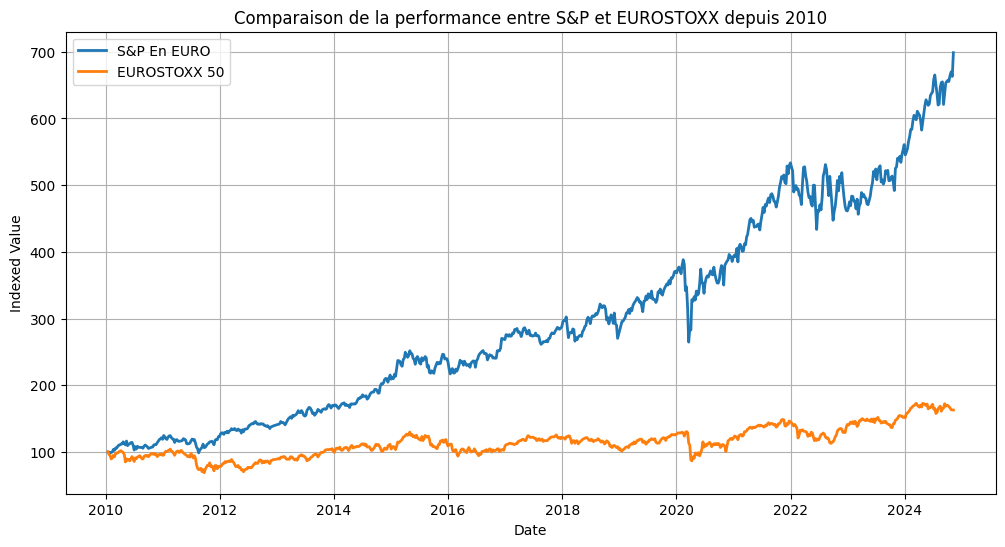

In [39]:
# Normalize both SPX_EUR and SX5E to start at 100
data_SX5E["SPX_EUR_Indexed"] = (data_SX5E["SPX_EUR"] / data_SX5E["SPX_EUR"].iloc[0]) * 100
data_SX5E["SX5E_Indexed"] = (data_SX5E["SX5E"] / data_SX5E["SX5E"].iloc[0]) * 100

# Plot the indexed values
plt.figure(figsize=(12, 6))
plt.plot(data_SX5E.index, data_SX5E["SPX_EUR_Indexed"], label="S&P En EURO", linewidth=2)
plt.plot(data_SX5E.index, data_SX5E["SX5E_Indexed"], label="EUROSTOXX 50", linewidth=2)
plt.title("Comparaison de la performance entre S&P et EUROSTOXX depuis 2010")
plt.xlabel("Date")
plt.ylabel("Indexed Value")
plt.legend()
plt.grid()
plt.savefig("./results/SPXvSSX5E.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. GET HISTORICAL FED DATA FOR TBILL

In [40]:
# Replace 'your_api_key' with your actual FRED API key
fred = Fred(api_key=FED_API_KEY)

# Example: Fetching the 5-Year Treasury Constant Maturity Rate ('DGS5')
tbill_5y_data = fred.get_series('DGS5')

In [41]:
tbill_5y_data

1962-01-02    3.88
1962-01-03    3.87
1962-01-04    3.86
1962-01-05    3.89
1962-01-08    3.91
              ... 
2024-11-19    4.25
2024-11-20    4.28
2024-11-21    4.30
2024-11-22    4.30
2024-11-25    4.17
Length: 16410, dtype: float64

In [42]:
tbill_5y_data.index = pd.to_datetime(tbill_5y_data.index)

In [43]:
tbill_5y_data.dropna(inplace=True)

In [44]:
# Convert Series to DataFrame
tbill_5y_df = pd.DataFrame(tbill_5y_data)

# Optionally, rename the column for clarity
tbill_5y_df.rename(columns={tbill_5y_df.columns[0]: '5Y_TBill_Yield'}, inplace=True)


In [45]:
data.index=pd.to_datetime(data.index)

In [46]:
# Perform a left join to match the dates in the original time series with the T-Bill data
matched_data = data.join(tbill_5y_df, how='left')

In [47]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield
Date,,,,,,,,,,
1999-01-08,1275.09,1.1580,1275.562846,1101.522320,0.037164,0.008562,0.037549,0.046509,False,4.72
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88
...,...,...,...,...,...,...,...,...,...,...
2024-10-25,5808.12,1.0981,9734.205034,8864.588867,-0.009642,0.016920,-0.009258,0.007794,False,4.07
2024-11-01,5728.80,1.0943,9605.011427,8777.310999,-0.013657,0.003461,-0.013272,-0.009846,False,4.22
2024-11-08,5995.54,1.0870,10055.926851,9251.082659,0.046561,0.006671,0.046946,0.053977,False,4.20


In [48]:
tbill_5y_data.tail(50)

2024-09-13    3.43
2024-09-16    3.41
2024-09-17    3.44
2024-09-18    3.47
2024-09-19    3.49
2024-09-20    3.48
2024-09-23    3.51
2024-09-24    3.47
2024-09-25    3.52
2024-09-26    3.55
2024-09-27    3.50
2024-09-30    3.58
2024-10-01    3.51
2024-10-02    3.55
2024-10-03    3.62
2024-10-04    3.81
2024-10-07    3.86
2024-10-08    3.86
2024-10-09    3.91
2024-10-10    3.91
2024-10-11    3.88
2024-10-15    3.86
2024-10-16    3.84
2024-10-17    3.90
2024-10-18    3.88
2024-10-21    3.98
2024-10-22    4.00
2024-10-23    4.05
2024-10-24    4.03
2024-10-25    4.07
2024-10-28    4.11
2024-10-29    4.11
2024-10-30    4.14
2024-10-31    4.15
2024-11-01    4.22
2024-11-04    4.17
2024-11-05    4.16
2024-11-06    4.27
2024-11-07    4.17
2024-11-08    4.20
2024-11-12    4.32
2024-11-13    4.30
2024-11-14    4.32
2024-11-15    4.30
2024-11-18    4.28
2024-11-19    4.25
2024-11-20    4.28
2024-11-21    4.30
2024-11-22    4.30
2024-11-25    4.17
dtype: float64

In [49]:
data
data.index

DatetimeIndex(['1999-01-08', '1999-01-14', '1999-01-22', '1999-01-29',
               '1999-02-05', '1999-02-12', '1999-02-19', '1999-02-26',
               '1999-03-05', '1999-03-12',
               ...
               '2024-09-20', '2024-09-27', '2024-10-04', '2024-10-10',
               '2024-10-18', '2024-10-25', '2024-11-01', '2024-11-08',
               '2024-11-15', '2024-11-22'],
              dtype='datetime64[ns]', name='Date', length=1348, freq=None)

In [50]:
data.columns

Index(['SPX', 'EURUSD', 'SPXTR', 'TRCompo', 'SPX_return', 'USDEUR_return',
       'SPXTR_return', 'TRCompo_return', 'Crash'],
      dtype='object')

In [51]:
# Define the bond duration
DURATION = 5

# Calculate daily yield changes
matched_data['Yield_Change'] = matched_data['5Y_TBill_Yield'].diff()

# Calculate daily MTM move based on duration and yield change
matched_data['5Y_TBILL_MTM_Move'] = -DURATION * matched_data['Yield_Change']

In [52]:
matched_data.dropna(inplace=True)

In [53]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move
Date,,,,,,,,,,,,
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48,-0.24,1.20
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54,0.06,-0.30
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55,0.01,-0.05
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88,0.33,-1.65
1999-02-12,1230.14,1.1303,1232.982885,1090.845691,-0.007471,-0.004086,-0.007087,-0.011128,False,4.96,0.08,-0.40
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-25,5808.12,1.0981,9734.205034,8864.588867,-0.009642,0.016920,-0.009258,0.007794,False,4.07,0.19,-0.95
2024-11-01,5728.80,1.0943,9605.011427,8777.310999,-0.013657,0.003461,-0.013272,-0.009846,False,4.22,0.15,-0.75
2024-11-08,5995.54,1.0870,10055.926851,9251.082659,0.046561,0.006671,0.046946,0.053977,False,4.20,-0.02,0.10


In [54]:
matched_data.describe()

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move
count,1335.000000,1335.000000,1335.000000,1335.000000,1335.000000,1335.000000,1335.000000,1335.000000,1335.000000,1335.000000,1335.000000
mean,2071.910195,1.186008,2924.855676,2550.502017,0.001474,-0.000010,0.001858,0.001991,2.829011,-0.000112,0.000562
std,1210.500199,0.155550,2156.636727,1995.422851,0.024555,0.012994,0.024555,0.026844,1.565899,0.127756,0.638781
min,683.380000,0.837200,838.442584,663.587324,-0.181955,-0.053917,-0.181570,-0.163427,0.210000,-0.520000,-3.100000
25%,1211.890000,1.085550,1364.850581,1138.803221,-0.010711,-0.008165,-0.010327,-0.012753,1.550000,-0.080000,-0.350000
50%,1458.950000,1.177100,1780.663509,1488.921961,0.002669,0.000000,0.003054,0.002625,2.640000,0.000000,0.000000
75%,2709.450000,1.303250,4007.784691,3410.837152,0.014530,0.007921,0.014915,0.017297,4.105000,0.070000,0.400000
max,5995.540000,1.594100,10055.926851,9251.082659,0.121017,0.058552,0.121402,0.161106,6.770000,0.620000,2.600000


In [55]:
matched_data['5Y_TBILL_CompoEUR_MTM_Move'] = (1+ matched_data['USDEUR_return'])*(1+matched_data['5Y_TBILL_MTM_Move'])-1

In [56]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move,5Y_TBILL_CompoEUR_MTM_Move
Date,,,,,,,,,,,,,
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48,-0.24,1.20,1.203800
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54,0.06,-0.30,-0.301514
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55,0.01,-0.05,-0.031959
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88,0.33,-1.65,-1.656177
1999-02-12,1230.14,1.1303,1232.982885,1090.845691,-0.007471,-0.004086,-0.007087,-0.011128,False,4.96,0.08,-0.40,-0.402452
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-25,5808.12,1.0981,9734.205034,8864.588867,-0.009642,0.016920,-0.009258,0.007794,False,4.07,0.19,-0.95,-0.949154
2024-11-01,5728.80,1.0943,9605.011427,8777.310999,-0.013657,0.003461,-0.013272,-0.009846,False,4.22,0.15,-0.75,-0.749135
2024-11-08,5995.54,1.0870,10055.926851,9251.082659,0.046561,0.006671,0.046946,0.053977,False,4.20,-0.02,0.10,0.107338


In [57]:
matched_data['strategy_return']=OBLIG_RATIO*matched_data['5Y_TBILL_CompoEUR_MTM_Move']+ (1-OBLIG_RATIO)*matched_data['TRCompo_return']

In [58]:
matched_data['strategy_return'].std()*np.sqrt(52)

2.7462716272824808

In [59]:
matched_data['strategy_return'].median()*260

1.8677116116221093

In [60]:
matched_data['strategy_return']

Date
1999-01-14    0.703360
1999-01-22   -0.177337
1999-01-29    0.006845
1999-02-05   -1.002412
1999-02-12   -0.245922
                ...   
2024-10-25   -0.566375
2024-11-01   -0.453419
2024-11-08    0.085994
2024-11-15   -0.303773
2024-11-22    0.000186
Name: strategy_return, Length: 1335, dtype: float64

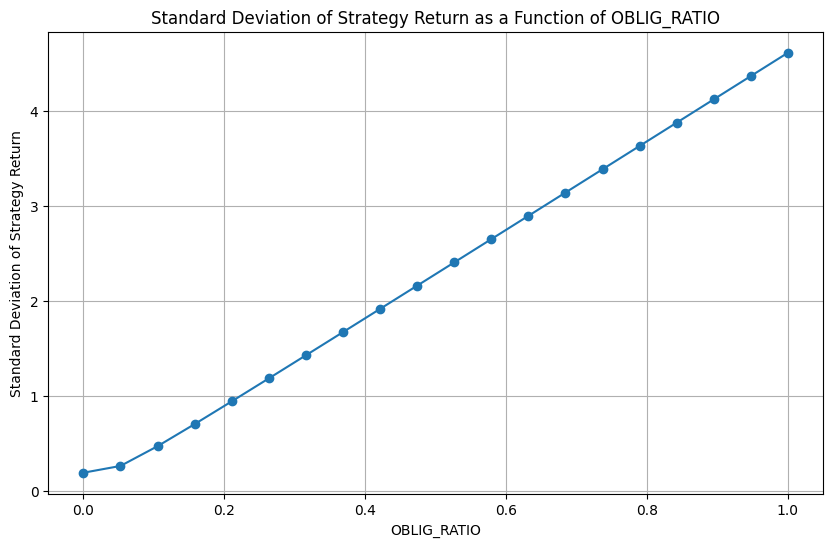

In [61]:
# Define a range of values for OBLIG_RATIO (e.g., from 0 to 1 with 0.1 increments)
oblig_ratios = np.linspace(0, 100, 20)/100
std_dev_values = []

# Loop through each OBLIG_RATIO and calculate the standard deviation of strategy_return
for ratio in oblig_ratios:
    # Calculate the strategy return for the given OBLIG_RATIO
    matched_data['strategy_return'] = (ratio * matched_data['5Y_TBILL_CompoEUR_MTM_Move'] +
                                       (1 - ratio) * matched_data['TRCompo_return'])
    # Calculate the standard deviation of the strategy return and store it
    std_dev_values.append(matched_data['strategy_return'].std()* np.sqrt(52))

# Plot OBLIG_RATIO vs. standard deviation of strategy_return
plt.figure(figsize=(10, 6))
plt.plot(oblig_ratios, std_dev_values, marker='o', linestyle='-')
plt.xlabel('OBLIG_RATIO')
plt.ylabel('Standard Deviation of Strategy Return')
plt.title('Standard Deviation of Strategy Return as a Function of OBLIG_RATIO')
plt.grid(True)
plt.show()

In [62]:
oblig_ratios

array([0.        , 0.05263158, 0.10526316, 0.15789474, 0.21052632,
       0.26315789, 0.31578947, 0.36842105, 0.42105263, 0.47368421,
       0.52631579, 0.57894737, 0.63157895, 0.68421053, 0.73684211,
       0.78947368, 0.84210526, 0.89473684, 0.94736842, 1.        ])

In [63]:
tbill_std = matched_data['5Y_TBILL_CompoEUR_MTM_Move'].std()
trcomp_std = matched_data['TRCompo_return'].std()
print(f"T-Bill Component Std: {tbill_std}, TRCompo Component Std: {trcomp_std}")


T-Bill Component Std: 0.6389914988124927, TRCompo Component Std: 0.026844335842230952


# 3. BACKTEST WITH ETF PORTFOLIO

In [64]:
data_etf = pd.read_excel(strategy_excel, sheet_name='Historique', skiprows=3)

In [65]:
data_etf

,Date,Close,Date.1,Close.1,Date.2,Close.2,Date.3,Close.3,Date.4,Close.4,...,Date.6,Close.6,Date.7,Close.7,Date.8,Close.8,Date.9,Close.9,Date.10,Close.10
0,2023-09-15 17:39:59.904,93.05,2023-09-15 17:26:00.096000,5.02,2023-09-15 17:39:59.904,93.43,2023-09-15 17:26:00.096,5.02,2023-09-15 17:26:00.096,5.02,...,2023-09-15 17:26:00.096,5.02,2023-09-15 16:30:00,466.41,2023-09-15 16:00:00.288,22.10,2023-09-15 16:30:00,5.96,2023-09-15 23:57:59.904,1.06720
1,2023-09-18 17:39:59.904,93.04,2023-09-18 17:26:00.096000,5.02,2023-09-18 17:39:59.904,93.35,2023-09-18 17:26:00.096,5.02,2023-09-18 17:26:00.096,5.01,...,2023-09-18 17:26:00.096,5.00,2023-09-18 16:30:00,466.14,2023-09-18 16:00:00.288,22.08,2023-09-18 16:30:00,5.96,2023-09-16 23:57:59.904,1.06720
2,2023-09-19 17:39:59.904,92.79,2023-09-19 17:26:00.096000,5.01,2023-09-19 17:39:59.904,93.23,2023-09-19 17:26:00.096,5.01,2023-09-19 17:26:00.096,5.01,...,2023-09-19 17:26:00.096,5.00,2023-09-19 16:30:00,462.58,2023-09-19 16:00:00.288,22.02,2023-09-19 16:30:00,5.95,2023-09-17 23:57:59.904,1.06677
3,2023-09-20 17:39:59.904,92.63,2023-09-20 17:26:00.096000,5.01,2023-09-20 17:39:59.904,93.09,2023-09-20 17:26:00.096,5.01,2023-09-20 17:26:00.096,5.01,...,2023-09-20 17:26:00.096,5.00,2023-09-20 16:30:00,465.21,2023-09-20 16:00:00.288,22.01,2023-09-20 16:30:00,5.96,2023-09-18 23:57:59.904,1.06919
4,2023-09-21 17:39:59.904,92.45,2023-09-21 17:26:00.096000,5.00,2023-09-21 17:39:59.904,93.33,2023-09-21 17:26:00.096,5.01,2023-09-21 17:26:00.096,5.01,...,2023-09-21 17:26:00.096,5.00,2023-09-21 16:30:00,455.54,2023-09-21 16:00:00.288,21.85,2023-09-21 16:30:00,5.91,2023-09-19 23:57:59.904,1.06814
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
433,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-22 23:57:59.904,1.04160
434,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-23 23:57:59.904,1.04170
435,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-24 23:57:59.904,1.04789
436,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-25 23:57:59.904,1.04620


In [66]:
data_etf

,Date,Close,Date.1,Close.1,Date.2,Close.2,Date.3,Close.3,Date.4,Close.4,...,Date.6,Close.6,Date.7,Close.7,Date.8,Close.8,Date.9,Close.9,Date.10,Close.10
0,2023-09-15 17:39:59.904,93.05,2023-09-15 17:26:00.096000,5.02,2023-09-15 17:39:59.904,93.43,2023-09-15 17:26:00.096,5.02,2023-09-15 17:26:00.096,5.02,...,2023-09-15 17:26:00.096,5.02,2023-09-15 16:30:00,466.41,2023-09-15 16:00:00.288,22.10,2023-09-15 16:30:00,5.96,2023-09-15 23:57:59.904,1.06720
1,2023-09-18 17:39:59.904,93.04,2023-09-18 17:26:00.096000,5.02,2023-09-18 17:39:59.904,93.35,2023-09-18 17:26:00.096,5.02,2023-09-18 17:26:00.096,5.01,...,2023-09-18 17:26:00.096,5.00,2023-09-18 16:30:00,466.14,2023-09-18 16:00:00.288,22.08,2023-09-18 16:30:00,5.96,2023-09-16 23:57:59.904,1.06720
2,2023-09-19 17:39:59.904,92.79,2023-09-19 17:26:00.096000,5.01,2023-09-19 17:39:59.904,93.23,2023-09-19 17:26:00.096,5.01,2023-09-19 17:26:00.096,5.01,...,2023-09-19 17:26:00.096,5.00,2023-09-19 16:30:00,462.58,2023-09-19 16:00:00.288,22.02,2023-09-19 16:30:00,5.95,2023-09-17 23:57:59.904,1.06677
3,2023-09-20 17:39:59.904,92.63,2023-09-20 17:26:00.096000,5.01,2023-09-20 17:39:59.904,93.09,2023-09-20 17:26:00.096,5.01,2023-09-20 17:26:00.096,5.01,...,2023-09-20 17:26:00.096,5.00,2023-09-20 16:30:00,465.21,2023-09-20 16:00:00.288,22.01,2023-09-20 16:30:00,5.96,2023-09-18 23:57:59.904,1.06919
4,2023-09-21 17:39:59.904,92.45,2023-09-21 17:26:00.096000,5.00,2023-09-21 17:39:59.904,93.33,2023-09-21 17:26:00.096,5.01,2023-09-21 17:26:00.096,5.01,...,2023-09-21 17:26:00.096,5.00,2023-09-21 16:30:00,455.54,2023-09-21 16:00:00.288,21.85,2023-09-21 16:30:00,5.91,2023-09-19 23:57:59.904,1.06814
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
433,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-22 23:57:59.904,1.04160
434,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-23 23:57:59.904,1.04170
435,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-24 23:57:59.904,1.04789
436,NaT,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT,NaN,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,2024-11-25 23:57:59.904,1.04620


In [67]:
# Convert all columns containing "Date" to datetime
date_columns = [col for col in data_etf.columns if col.startswith("Date")]
for col in date_columns:
    data_etf[col] = pd.to_datetime(data_etf[col]).dt.strftime('%Y-%m-%d')

# Find the intersection of all dates across the "Date" columns
matching_dates = set(data_etf[date_columns[0]])
for col in date_columns[1:]:
    matching_dates &= set(data_etf[col])

# Sort the matching dates for proper time series indexing
matching_dates = sorted(matching_dates)

# Filter rows where all dates match the intersection
filtered_data = data_etf[data_etf[date_columns[0]].isin(matching_dates)]

# Set the first "Date" column as the index
time_series_data = filtered_data.set_index(date_columns[0])

# Drop redundant "Date" columns to clean up
time_series_data = time_series_data.drop(columns=date_columns[1:])

# Display the resulting DataFrame
time_series_data



,Close,Close.1,Close.2,Close.3,Close.4,Close.5,Close.6,Close.7,Close.8,Close.9,Close.10
Date,,,,,,,,,,,
2023-09-15,93.05,5.02,93.43,5.02,5.02,93.70,5.02,466.41,22.10,5.96,1.06720
2023-09-18,93.04,5.02,93.35,5.02,5.01,93.65,5.00,466.14,22.08,5.96,1.06720
2023-09-19,92.79,5.01,93.23,5.01,5.01,93.45,5.00,462.58,22.02,5.95,1.06677
2023-09-20,92.63,5.01,93.09,5.01,5.01,93.28,5.00,465.21,22.01,5.96,1.06919
2023-09-25,93.29,5.00,94.16,5.01,5.01,94.06,4.99,452.21,21.82,5.90,1.06606
...,...,...,...,...,...,...,...,...,...,...,...
2024-11-12,101.95,5.38,NaN,5.27,5.31,NaN,5.41,609.47,23.60,6.70,1.07190
2024-11-13,102.17,5.38,NaN,5.27,5.32,NaN,5.42,605.71,23.67,6.71,1.07340
2024-11-14,102.29,5.39,NaN,5.27,5.32,NaN,5.42,610.67,23.75,6.71,1.07363


In [68]:
time_series_data.isna().sum()

Close        0
Close.1      0
Close.2     19
Close.3      0
Close.4      0
Close.5     15
Close.6      0
Close.7      0
Close.8      0
Close.9      0
Close.10     0
dtype: int64

In [69]:
# Define the new column names for the "Close" columns
new_column_names = {
    "Close": "28ID",
    "Close.1": "IB27",
    "Close.2": "26ID",
    "Close.3": "IB25",
    "Close.4": "CEBE",
    "Close.5": "DI27",
    "Close.6": "IVOA",
    "Close.7": "CSPX",
    "Close.8": "IHYA",
    "Close.9": "ID30",
    "Close.10": "EURUSD",
}

# Rename the columns in the DataFrame
time_series_data = time_series_data.rename(columns=new_column_names)



In [70]:
time_series_data

,28ID,IB27,26ID,IB25,CEBE,DI27,IVOA,CSPX,IHYA,ID30,EURUSD
Date,,,,,,,,,,,
2023-09-15,93.05,5.02,93.43,5.02,5.02,93.70,5.02,466.41,22.10,5.96,1.06720
2023-09-18,93.04,5.02,93.35,5.02,5.01,93.65,5.00,466.14,22.08,5.96,1.06720
2023-09-19,92.79,5.01,93.23,5.01,5.01,93.45,5.00,462.58,22.02,5.95,1.06677
2023-09-20,92.63,5.01,93.09,5.01,5.01,93.28,5.00,465.21,22.01,5.96,1.06919
2023-09-25,93.29,5.00,94.16,5.01,5.01,94.06,4.99,452.21,21.82,5.90,1.06606
...,...,...,...,...,...,...,...,...,...,...,...
2024-11-12,101.95,5.38,NaN,5.27,5.31,NaN,5.41,609.47,23.60,6.70,1.07190
2024-11-13,102.17,5.38,NaN,5.27,5.32,NaN,5.42,605.71,23.67,6.71,1.07340
2024-11-14,102.29,5.39,NaN,5.27,5.32,NaN,5.42,610.67,23.75,6.71,1.07363


In [71]:
time_series_data_cleaned = time_series_data.dropna(axis=1)

In [72]:
time_series_data_cleaned

,28ID,IB27,IB25,CEBE,IVOA,CSPX,IHYA,ID30,EURUSD
Date,,,,,,,,,
2023-09-15,93.05,5.02,5.02,5.02,5.02,466.41,22.10,5.96,1.06720
2023-09-18,93.04,5.02,5.02,5.01,5.00,466.14,22.08,5.96,1.06720
2023-09-19,92.79,5.01,5.01,5.01,5.00,462.58,22.02,5.95,1.06677
2023-09-20,92.63,5.01,5.01,5.01,5.00,465.21,22.01,5.96,1.06919
2023-09-25,93.29,5.00,5.01,5.01,4.99,452.21,21.82,5.90,1.06606
...,...,...,...,...,...,...,...,...,...
2024-11-12,101.95,5.38,5.27,5.31,5.41,609.47,23.60,6.70,1.07190
2024-11-13,102.17,5.38,5.27,5.32,5.42,605.71,23.67,6.71,1.07340
2024-11-14,102.29,5.39,5.27,5.32,5.42,610.67,23.75,6.71,1.07363


In [73]:
# List of columns in USD (based on your description)
usd_columns = ["DI27", "IVOA", "CSPX", "IHYA", "ID30"]

# Ensure the `EURUSD` column is available and convert to EUR
for col in usd_columns:
    if col in time_series_data_cleaned.columns:
        time_series_data_cleaned[col] = time_series_data[col] / time_series_data["EURUSD"]

/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_1795/1381873932.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  time_series_data_cleaned[col] = time_series_data[col] / time_series_data["EURUSD"]


In [74]:
time_series_data_cleaned

,28ID,IB27,IB25,CEBE,IVOA,CSPX,IHYA,ID30,EURUSD
Date,,,,,,,,,
2023-09-15,93.05,5.02,5.02,5.02,4.703898,437.040855,20.708396,5.584708,1.06720
2023-09-18,93.04,5.02,5.02,5.01,4.685157,436.787856,20.689655,5.584708,1.06720
2023-09-19,92.79,5.01,5.01,5.01,4.687046,433.626742,20.641750,5.577585,1.06677
2023-09-20,92.63,5.01,5.01,5.01,4.676437,435.105080,20.585677,5.574313,1.06919
2023-09-25,93.29,5.00,5.01,5.01,4.680787,424.188132,20.467891,5.534398,1.06606
...,...,...,...,...,...,...,...,...,...
2024-11-12,101.95,5.38,5.27,5.31,5.047113,568.588488,22.016979,6.250583,1.07190
2024-11-13,102.17,5.38,5.27,5.32,5.049376,564.291038,22.051425,6.251165,1.07340
2024-11-14,102.29,5.39,5.27,5.32,5.048294,568.789993,22.121215,6.249825,1.07363


In [75]:
time_series_data_cleaned.index = pd.to_datetime(time_series_data_cleaned.index)

In [76]:
time_series_data_cleaned.index

DatetimeIndex(['2023-09-15', '2023-09-18', '2023-09-19', '2023-09-20',
               '2023-09-25', '2023-09-26', '2023-09-27', '2023-09-28',
               '2023-09-29', '2023-10-02',
               ...
               '2024-11-01', '2024-11-05', '2024-11-06', '2024-11-08',
               '2024-11-11', '2024-11-12', '2024-11-13', '2024-11-14',
               '2024-11-15', '2024-11-20'],
              dtype='datetime64[ns]', name='Date', length=225, freq=None)

In [77]:
# Create a full date range from the first to the last date
full_date_range = pd.date_range(start=time_series_data_cleaned.index.min(), end=time_series_data_cleaned.index.max(), freq='D')



In [78]:
full_date_range

DatetimeIndex(['2023-09-15', '2023-09-16', '2023-09-17', '2023-09-18',
               '2023-09-19', '2023-09-20', '2023-09-21', '2023-09-22',
               '2023-09-23', '2023-09-24',
               ...
               '2024-11-11', '2024-11-12', '2024-11-13', '2024-11-14',
               '2024-11-15', '2024-11-16', '2024-11-17', '2024-11-18',
               '2024-11-19', '2024-11-20'],
              dtype='datetime64[ns]', length=433, freq='D')

In [79]:
# Reindex the DataFrame to include all dates
time_series_data_cleaned = time_series_data_cleaned.reindex(full_date_range)

# Interpolate missing values
df_interpolated = time_series_data_cleaned.interpolate(method='linear')


In [80]:
time_series_data_cleaned=time_series_data_cleaned.reindex(full_date_range)

In [81]:
time_series_data_interpolate = time_series_data_cleaned.interpolate()

In [82]:
data_port = pd.read_excel(strategy_excel, sheet_name='Portfolio', usecols=[0, 1, 2])

In [83]:
daily_returns_etf = time_series_data_interpolate.pct_change()

In [84]:
daily_returns_etf.dropna(inplace=True)

In [85]:
daily_returns_etf

,28ID,IB27,IB25,CEBE,IVOA,CSPX,IHYA,ID30,EURUSD
2023-09-16,-0.000036,0.000000,0.000000,-0.000664,-0.001328,-0.000193,-0.000302,0.000000,0.000000
2023-09-17,-0.000036,0.000000,0.000000,-0.000664,-0.001330,-0.000193,-0.000302,0.000000,0.000000
2023-09-18,-0.000036,0.000000,0.000000,-0.000665,-0.001332,-0.000193,-0.000302,0.000000,0.000000
2023-09-19,-0.002687,-0.001992,-0.001992,0.000000,0.000403,-0.007237,-0.002315,-0.001275,-0.000403
2023-09-20,-0.001724,0.000000,0.000000,0.000000,-0.002263,0.003409,-0.002717,-0.000587,0.002269
...,...,...,...,...,...,...,...,...,...
2024-11-16,0.001271,0.000371,-0.000379,0.000376,-0.000765,0.001876,-0.002780,-0.000392,0.001881
2024-11-17,0.001269,0.000371,-0.000379,0.000376,-0.000766,0.001873,-0.002788,-0.000392,0.001878
2024-11-18,0.001268,0.000371,-0.000379,0.000376,-0.000766,0.001869,-0.002796,-0.000392,0.001874
2024-11-19,0.001266,0.000371,-0.000379,0.000376,-0.000767,0.001866,-0.002804,-0.000392,0.001871


In [86]:
OBLIG_RATIO=0.6

In [87]:
oblig_weight= OBLIG_RATIO/7
equity_weight=1-OBLIG_RATIO

In [88]:
port_weight= {"28ID":oblig_weight,	"IB27":oblig_weight,		"IB25":oblig_weight,	"CEBE":oblig_weight,	
                "IVOA":oblig_weight,	"CSPX":equity_weight,	"IHYA":oblig_weight,	"ID30":oblig_weight,	"EURUSD":0}

In [89]:
# Ensure weights match the columns in daily_returns
weights_series = pd.Series(port_weight)

# Compute the weighted daily returns for each column
weighted_returns = daily_returns_etf.multiply(weights_series, axis=1)

# Sum the weighted returns to get the portfolio's daily return
portfolio_daily_returns = weighted_returns.sum(axis=1)

In [90]:
weights_series

28ID      0.085714
IB27      0.085714
IB25      0.085714
CEBE      0.085714
IVOA      0.085714
CSPX      0.400000
IHYA      0.085714
ID30      0.085714
EURUSD    0.000000
dtype: float64

In [91]:
weights_series.sum()

1.0

In [92]:
portfolio_daily_returns

2023-09-16   -0.000277
2023-09-17   -0.000277
2023-09-18   -0.000277
2023-09-19   -0.003740
2023-09-20    0.000739
                ...   
2024-11-16    0.000553
2024-11-17    0.000551
2024-11-18    0.000549
2024-11-19    0.000547
2024-11-20    0.000544
Freq: D, Length: 432, dtype: float64

In [93]:
daily_returns_etf.describe()

,28ID,IB27,IB25,CEBE,IVOA,CSPX,IHYA,ID30,EURUSD
count,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000
mean,0.000237,0.000170,0.000113,0.000139,0.000152,0.000694,0.000126,0.000265,0.000040
std,0.002339,0.001305,0.000729,0.000954,0.002765,0.004987,0.003312,0.003115,0.002170
min,-0.008325,-0.005736,-0.001992,-0.003992,-0.010043,-0.014282,-0.014972,-0.010966,-0.008626
25%,-0.001011,0.000000,0.000000,0.000000,-0.000766,-0.001884,-0.001560,-0.000895,-0.000586
50%,0.000105,0.000000,0.000000,0.000000,-0.000021,0.000226,0.000019,0.000044,0.000000
75%,0.001134,0.000481,0.000096,0.000272,0.001014,0.002719,0.001297,0.001193,0.000813
max,0.016261,0.007828,0.003929,0.004008,0.013709,0.026067,0.011592,0.021070,0.010145


In [94]:
# Calculate standard deviation (volatility) of portfolio returns
portfolio_volatility = round(portfolio_daily_returns.std()*np.sqrt(365)*100,2)

# Calculate median of portfolio returns
portfolio_annual_return = round(portfolio_daily_returns.mean()*365*100,2)

portfolio_sharp_ratio= round(portfolio_annual_return/portfolio_volatility,2)

# Display the results
print(f"Portfolio Annual Volatility: {portfolio_volatility}%")
print(f"Portfolio Annual Return: {portfolio_annual_return}%")
print(f"Portfolio Sharp Ratio: {portfolio_sharp_ratio}")

Portfolio Annual Volatility: 4.74%
Portfolio Annual Return: 13.89%
Portfolio Sharp Ratio: 2.93


In [95]:
# Define the starting index value
starting_index = 100

# Compute the portfolio index over time
portfolio_index = (1 + portfolio_daily_returns).cumprod() * starting_index




In [96]:
portfolio_index

2023-09-16     99.972314
2023-09-17     99.944615
2023-09-18     99.916902
2023-09-19     99.543221
2023-09-20     99.616761
                 ...    
2024-11-16    117.451773
2024-11-17    117.516509
2024-11-18    117.581010
2024-11-19    117.645276
2024-11-20    117.709306
Freq: D, Length: 432, dtype: float64

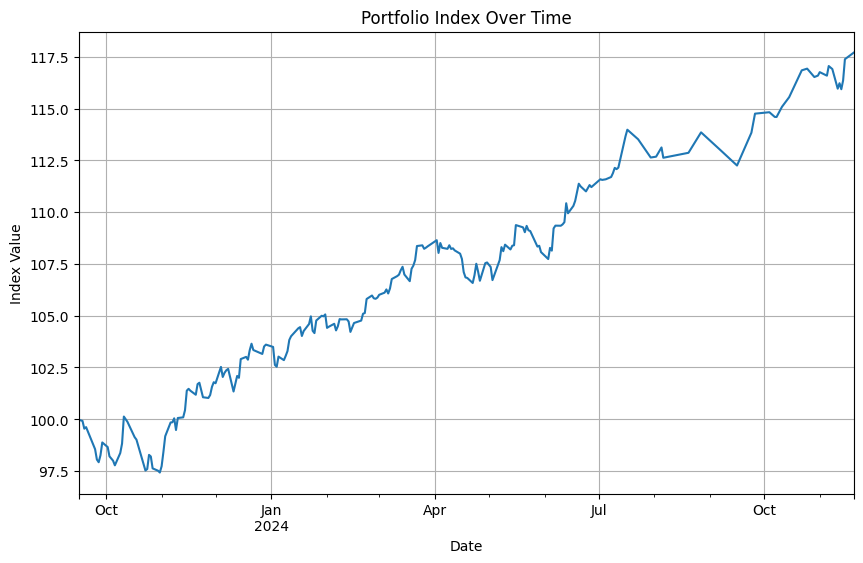

In [97]:

# Assuming your series is called `portfolio_index`
portfolio_index.plot(figsize=(10, 6), title="Portfolio Index Over Time", ylabel="Index Value", xlabel="Date")
plt.grid()
plt.savefig("./results/strategybackest.png", dpi=300, bbox_inches="tight")
plt.show()


# 4. PORTFOLIO WEIGHTS OPTIMIZATION

In [280]:
portfolio_daily_returns_opt=daily_returns_etf.drop(columns='EURUSD')

# Define the risk-free rate (adjust to your data)
risk_free_rate = 0.0

# Calculate mean returns and covariance matrix
mean_returns = portfolio_daily_returns_opt.mean()
cov_matrix = portfolio_daily_returns_opt.cov()

# Number of assets
num_assets = len(portfolio_daily_returns_opt.columns)

# Initial guess for weights
initial_weights = np.array([1 / num_assets] * num_assets)

# Define portfolio return and volatility
def portfolio_performance(weights, mean_returns, cov_matrix):
    portfolio_return = np.sum(weights * mean_returns)
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return portfolio_return, portfolio_volatility

# Objective function: negative Sharpe ratio
def negative_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate):
    portfolio_return, portfolio_volatility = portfolio_performance(weights, mean_returns, cov_matrix)
    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility
    return -sharpe_ratio

# Constraints: weights sum to 1
constraints = ({'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1})

# Bounds: weights between 0 and 1
bounds = tuple((0, 1) for _ in range(num_assets))

# Optimize weights
result = minimize(
    fun=negative_sharpe_ratio,
    x0=initial_weights,
    args=(mean_returns, cov_matrix, risk_free_rate),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# Extract optimal weights
optimal_weights = result.x

# Display results
print("Optimal Weights:", optimal_weights)
print("Maximum Sharpe Ratio:", -result.fun)


Optimal Weights: [1.06151330e-01 2.90673675e-01 3.23555638e-01 2.31722630e-01
 7.20520106e-17 4.78967265e-02 2.59666420e-17 9.20352119e-17]
Maximum Sharpe Ratio: 0.2592277081763116


# 5. ANALYSE JP MORGAN STRATEGY

In [333]:
first_date = portfolio_index.index.min().strftime('%Y-%m-%d')
last_date = portfolio_index.index.max().strftime('%Y-%m-%d')
portfolio_index.index = pd.to_datetime(portfolio_index.index)

In [334]:
# Create a Ticker object for Apple Inc.
jp_opcvm = yf.Ticker("0P0001K15I.F")

# Get historical market data
jp_opcvm_hist = jp_opcvm.history(period="3y")



In [343]:
def computeTicker(portfolio_index, jp_opcvm_hist):
    first_date = portfolio_index.index.min().strftime('%Y-%m-%d')
    last_date = portfolio_index.index.max().strftime('%Y-%m-%d')
    portfolio_index.index = pd.to_datetime(portfolio_index.index)
    jp_opcvm_hist.index = jp_opcvm_hist.index.strftime('%Y-%m-%d')
    jp_opcvm_hist=jp_opcvm_hist['Close']
    filtered_jp_opcvm_series = jp_opcvm_hist.loc[first_date:last_date]
    index_filtered_jp_opcvm_series = (filtered_jp_opcvm_series / filtered_jp_opcvm_series.iloc[0]) * 100
    index_filtered_jp_opcvm_series.index = pd.to_datetime(index_filtered_jp_opcvm_series.index)
    start_date_series1 = index_filtered_jp_opcvm_series.index.min()
    start_date_series2 = portfolio_index.index.min()
    
    # Use the later of the two start dates
    common_start_date = max(start_date_series1, start_date_series2)
    aligned_index_series1 = index_filtered_jp_opcvm_series.loc[common_start_date:]
    aligned_index_series2 = portfolio_index.loc[common_start_date:]
    aligned_data = pd.DataFrame({
    "Benchmark": aligned_index_series1,
    "US Strategy": aligned_index_series2
    }).dropna()  # Drop rows with missing data
        # Compute the total number of years
    start_date = index_filtered_jp_opcvm_series.index.min()
    end_date = index_filtered_jp_opcvm_series.index.max()
    n_years = (end_date - start_date).days / 365.25
    
    # Calculate annualized return
    initial_value = index_filtered_jp_opcvm_series.iloc[0]
    final_value = index_filtered_jp_opcvm_series.iloc[-1]
    annualized_return = (final_value / initial_value) ** (1 / n_years) - 1
    
    # Calculate daily returns
    daily_returns = index_filtered_jp_opcvm_series.pct_change()
    
    # Calculate annualized volatility
    annualized_volatility = daily_returns.std() * np.sqrt(252)
    
    sharp_ratio_jp=round(annualized_return/annualized_volatility,1)
    # Display results
    print(f"Annualized Return: {annualized_return * 100:.2f}%")
    print(f"Annualized Volatility: {annualized_volatility * 100:.2f}%")
    print(f"Sharp Ratio: {sharp_ratio_jp :.2f}")
    return aligned_data

In [336]:
aligned_data=computeTicker(portfolio_index, jp_opcvm_hist)

Annualized Return: 8.66%
Annualized Volatility: 10.34%
Sharp Ratio: 0.80


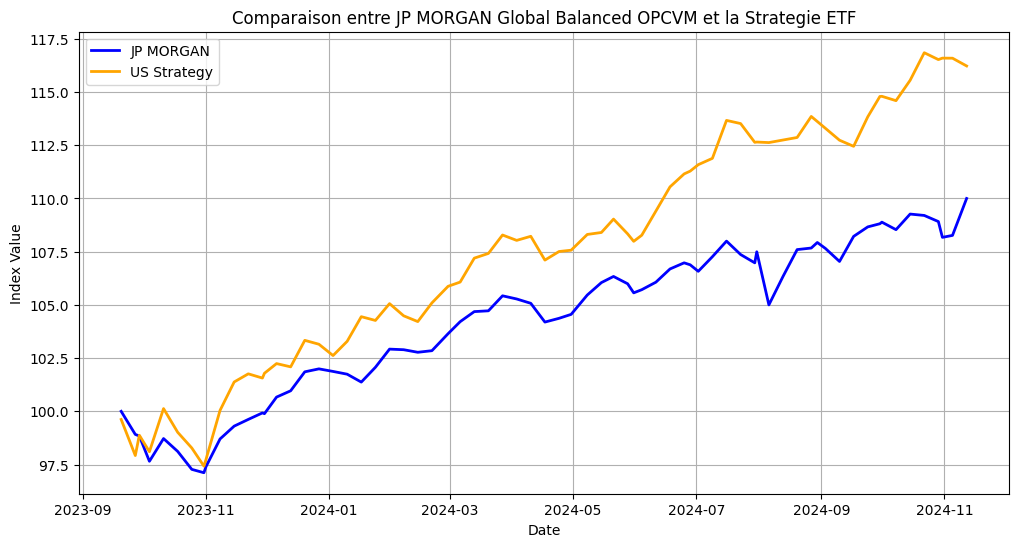

In [337]:
plt.figure(figsize=(12, 6))
plt.plot(aligned_data.index, aligned_data["JP MORGAN"], label="JP MORGAN", linewidth=2, color="blue")
plt.plot(aligned_data.index, aligned_data["US Strategy"], label="US Strategy", linewidth=2, color="orange")
plt.title("Comparaison entre JP MORGAN Global Balanced OPCVM et la Strategie ETF")
plt.xlabel("Date")
plt.ylabel("Index Value")
plt.legend()
plt.grid()
plt.savefig("./results/strategyvsjp.png", dpi=300, bbox_inches="tight")
plt.show()

In [346]:
# Create a Ticker object for Apple Inc.
eurose_opcvm = yf.Ticker("FR0007051040")

# Get historical market data
eurose_opcvm_hist = eurose_opcvm.history(period="3y")


In [347]:
eurose_opcvm_hist

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,
2021-11-22 00:00:00+01:00,398.160004,398.160004,398.160004,398.160004,0,0.0,0.0,0.0
2021-11-23 00:00:00+01:00,397.510010,397.510010,397.510010,397.510010,0,0.0,0.0,0.0
2021-11-24 00:00:00+01:00,397.390015,397.390015,397.390015,397.390015,0,0.0,0.0,0.0
2021-11-25 00:00:00+01:00,397.459991,397.459991,397.459991,397.459991,0,0.0,0.0,0.0
2021-11-26 00:00:00+01:00,392.109985,392.109985,392.109985,392.109985,0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2024-11-12 00:00:00+01:00,431.459991,431.459991,431.459991,431.459991,0,0.0,0.0,0.0
2024-11-13 00:00:00+01:00,430.769989,430.769989,430.769989,430.769989,0,0.0,0.0,0.0
2024-11-14 00:00:00+01:00,431.869995,431.869995,431.869995,431.869995,0,0.0,0.0,0.0


In [348]:
aligned_data=computeTicker(portfolio_index, eurose_opcvm_hist)

Annualized Return: 4.75%
Annualized Volatility: 2.63%
Sharp Ratio: 1.80


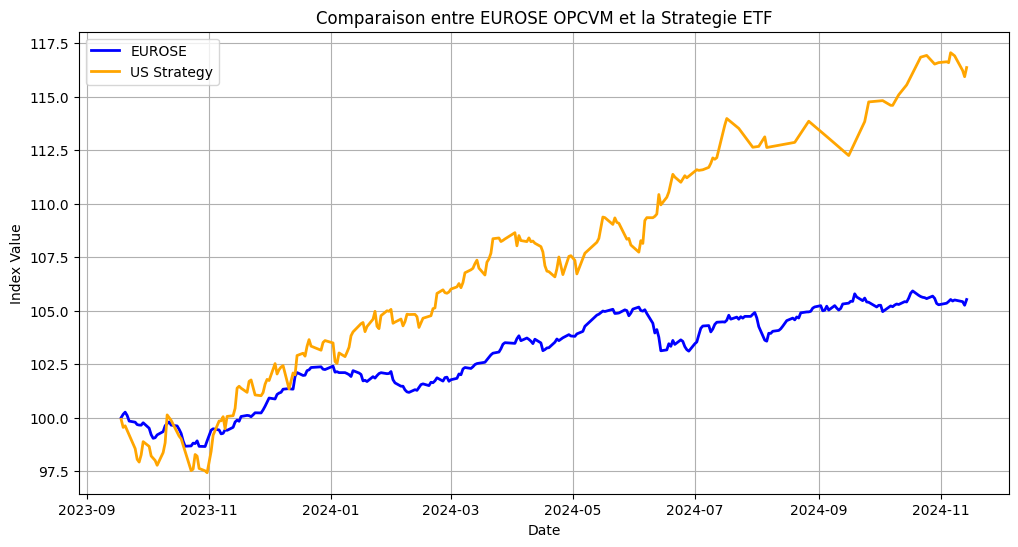

In [350]:
plt.figure(figsize=(12, 6))
plt.plot(aligned_data.index, aligned_data["Benchmark"], label="EUROSE", linewidth=2, color="blue")
plt.plot(aligned_data.index, aligned_data["US Strategy"], label="US Strategy", linewidth=2, color="orange")
plt.title("Comparaison entre EUROSE OPCVM et la Strategie ETF")
plt.xlabel("Date")
plt.ylabel("Index Value")
plt.legend()
plt.grid()
plt.savefig("./results/strategyvseurose.png", dpi=300, bbox_inches="tight")
plt.show()

In [99]:
# Create a Ticker object for Apple Inc.
vanguard_etf = yf.Ticker("IE00BMVB5M21.SG")

# Get historical market data
vanguard_etf = vanguard_etf.history(period="2y")


IE00BMVB5M21.SG: No price data found, symbol may be delisted (period=2y)
